<a href="https://colab.research.google.com/github/DariaToguleva/vip-curriculum-starter/blob/main/VIP_Exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
!pip install -q basicts==1.1.0 easy-torch==1.3.3 --no-deps
!pip install -q easydict setproctitle tables
import sys; print(sys.version)
from google.colab import drive
drive.mount('/content/gdrive')
!nvidia-smi

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Mounted at /content/gdrive
Mon Oct 26 18:46:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                   

In [16]:
!find /content/drive/MyDrive -name "*.npz" 2>/dev/null

In [17]:
import json, os, platform, time
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn

import basicts
from basicts import BasicTSLauncher
from basicts.configs import BasicTSForecastingConfig, BasicTSModelConfig
from basicts.data.base_dataset import BasicTSDataset
from basicts.models.PatchTST import PatchTSTConfig, PatchTSTForForecasting
from basicts.runners.callback import BasicTSCallback

DATA = "/content/gdrive/MyDrive/Colab Notebooks/vip/data"
OUT = "/content/gdrive/MyDrive/Colab Notebooks/vip/starter_runs"
GPUS = "0"
NUM_EPOCHS = 20
os.makedirs(OUT, exist_ok=True)
versions = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "basicts": basicts.__version__,
    "numpy": np.__version__,
}
print(versions)
json.dump(versions, open(f"{OUT}/versions.json", "w"), indent=2)

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'cuda': '13.0', 'gpu': 'Tesla T4', 'basicts': '1.1.0', 'numpy': '2.1.3'}


In [18]:
INPUT_LEN, OUTPUT_LEN = 96, 24


class SineDataset(BasicTSDataset):
    def __init__(self, dataset_name: str, mode, data_dir: str, memmap: bool = False):
        super().__init__(dataset_name, mode, memmap)
        mode = getattr(mode, "value", mode)
        z = np.load(os.path.join(data_dir, f"{mode}.npz"))
        values = z["values"].astype(np.float32)
        self.x = torch.from_numpy(values[:, :INPUT_LEN, None])
        self.y = torch.from_numpy(values[:, INPUT_LEN:, None])
        self.noise = z["noise"]
        self.order = np.arange(len(values))

    def set_order(self, order):
        self.order = np.asarray(order)

    def __getitem__(self, i):
        j = self.order[i]
        return {"inputs": self.x[j], "targets": self.y[j]}

    def __len__(self):
        return len(self.order)

    @property
    def data(self):
        return self.x.numpy()

In [19]:
@dataclass
class LinearConfig(BasicTSModelConfig):
    input_len: int = INPUT_LEN
    output_len: int = OUTPUT_LEN


class LinearModel(nn.Module):
    def __init__(self, config: LinearConfig):
        super().__init__()
        self.fc = nn.Linear(config.input_len, config.output_len, bias=True)

    def forward(self, inputs):
        return self.fc(inputs[..., 0]).unsqueeze(-1)


@dataclass
class MLPConfig(BasicTSModelConfig):
    input_len: int = INPUT_LEN
    output_len: int = OUTPUT_LEN
    hidden_size: int = 64


class MLPModel(nn.Module):
    def __init__(self, config: MLPConfig):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(config.input_len, config.hidden_size, bias=True),
            nn.ReLU(),
            nn.Linear(config.hidden_size, config.output_len, bias=True),
        )

    def forward(self, inputs):
        return self.net(inputs[..., 0]).unsqueeze(-1)


def patchtst_config():
    return PatchTSTConfig(
        input_len=INPUT_LEN, output_len=OUTPUT_LEN, num_features=1,
        patch_len=16, patch_stride=8, hidden_size=32, n_heads=4,
        num_layers=2, intermediate_size=128, norm_type="layer_norm",
        use_revin=False, decomp=False,
        attn_dropout=0.0, fc_dropout=0.0, head_dropout=0.0,
    )


MODELS = {
    "Linear": (LinearModel, LinearConfig),
    "MLP": (MLPModel, MLPConfig),
    "PatchTST": (PatchTSTForForecasting, patchtst_config),
}

In [20]:
@dataclass
class LinearConfig(BasicTSModelConfig):
    input_len: int = INPUT_LEN
    output_len: int = OUTPUT_LEN


class LinearModel(nn.Module):
    def __init__(self, config: LinearConfig):
        super().__init__()
        self.fc = nn.Linear(config.input_len, config.output_len, bias=True)

    def forward(self, inputs):                                       # [B, 96, 1]
        return self.fc(inputs[..., 0]).unsqueeze(-1)                 # [B, 24, 1]


@dataclass
class MLPConfig(BasicTSModelConfig):
    input_len: int = INPUT_LEN
    output_len: int = OUTPUT_LEN
    hidden_size: int = 64


class MLPModel(nn.Module):
    def __init__(self, config: MLPConfig):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(config.input_len, config.hidden_size, bias=True),
            nn.ReLU(),
            nn.Linear(config.hidden_size, config.output_len, bias=True),
        )

    def forward(self, inputs):
        return self.net(inputs[..., 0]).unsqueeze(-1)


def patchtst_config():
    return PatchTSTConfig(
        input_len=INPUT_LEN, output_len=OUTPUT_LEN, num_features=1,
        patch_len=16, patch_stride=8, hidden_size=32, n_heads=4,
        num_layers=2, intermediate_size=128, norm_type="layer_norm",
        use_revin=False, decomp=False,
        attn_dropout=0.0, fc_dropout=0.0, head_dropout=0.0,
    )


MODELS = {
    "Linear": (LinearModel, LinearConfig),
    "MLP": (MLPModel, MLPConfig),
    "PatchTST": (PatchTSTForForecasting, patchtst_config),
}

In [21]:
BATCH_SIZE = 32
train_noise = np.load(f"{DATA}/train.npz")["noise"]
low_idx = np.where(np.isclose(train_noise, 0.1))[0]
high_idx = np.where(np.isclose(train_noise, 0.5))[0]

# batch membership is fixed once (seed 0) and shared by every run
_rng = np.random.default_rng(0)
low_batches = _rng.permutation(low_idx).reshape(-1, BATCH_SIZE)      # 16 x 32
high_batches = _rng.permutation(high_idx).reshape(-1, BATCH_SIZE)    # 16 x 32
BATCHES = np.concatenate([low_batches, high_batches])                 # batch ids 0-15 low, 16-31 high
BATCH_NOISE = np.array([0.1] * len(low_batches) + [0.5] * len(high_batches))


def batch_order(condition, rng):
    low = np.arange(len(low_batches))
    high = np.arange(len(low_batches), len(BATCHES))
    if condition == "random":
        return rng.permutation(len(BATCHES))
    if condition == "low_first":
        return np.concatenate([rng.permutation(low), rng.permutation(high)])
    raise ValueError(condition)

In [22]:
class Experiment(BasicTSCallback):
    def __init__(self, condition, order_seed, data_dir):
        self.condition = condition
        self.rng = np.random.default_rng(order_seed)   # ordering randomness, separate from torch init
        self.val = np.load(f"{data_dir}/val.npz")
        self.test = np.load(f"{data_dir}/test.npz")
        self.epoch_batch_noise, self.val_curve, self.epoch_times = [], [], []
        self.updates = 0

    def _sync(self):
        if torch.cuda.is_available():
            torch.cuda.synchronize()

    def on_train_start(self, runner, *args, **kwargs):
        sd = runner.model.state_dict()
        self.init_checksum = float(sum(v.double().sum().item() for v in sd.values()))

    def on_epoch_start(self, runner, *args, **kwargs):
        order = batch_order(self.condition, self.rng)
        self.epoch_batch_noise.append(BATCH_NOISE[order].tolist())
        runner.train_data_loader.dataset.set_order(BATCHES[order].ravel())
        self._sync()
        self.t0 = time.perf_counter()

    def on_step_end(self, runner, *args, **kwargs):
        self.updates += 1
        # BasicTS 1.1.0 stops one update early (639 instead of 640), so we give it one
        # extra epoch and stop it ourselves after exactly NUM_EPOCHS * 32 updates.
        if self.updates == NUM_EPOCHS * len(BATCHES):
            runner.should_training_stop = True

    def on_epoch_end(self, runner, *args, **kwargs):
        self._sync()
        self.epoch_times.append(time.perf_counter() - self.t0)   # before validation runs
        self.val_curve.append((self.updates, self._evaluate(runner.model, self.val)["MSE"]))

    def on_train_end(self, runner, *args, **kwargs):
        self.final_test = self._evaluate(runner.model, self.test, keep_preds=True)

    @torch.no_grad()
    def _evaluate(self, model, z, keep_preds=False):
        model.eval()
        device = next(model.parameters()).device
        v = torch.from_numpy(z["values"].astype(np.float32)).to(device)
        pred = model(v[:, :INPUT_LEN, None])[..., 0]
        err = (pred - v[:, INPUT_LEN:]).cpu().numpy()
        model.train()
        out = {"MSE": float((err ** 2).mean()), "MAE": float(np.abs(err).mean())}
        for lvl in (0.1, 0.5):
            g = np.isclose(z["noise"], lvl)
            out[f"MSE_{lvl}"] = float((err[g] ** 2).mean())
            out[f"MAE_{lvl}"] = float(np.abs(err[g]).mean())
        if keep_preds:
            out["preds"] = pred.cpu().numpy()
        return out

In [23]:
def run(model_name, condition, seed):
    cls, cfg_fn = MODELS[model_name]
    exp = Experiment(condition, order_seed=1000 + seed, data_dir=DATA)
    cfg = BasicTSForecastingConfig(
        model=cls,
        model_config=cfg_fn(),
        dataset_name="sine_starter",
        dataset_type=SineDataset,
        dataset_params={"dataset_name": "sine_starter", "data_dir": DATA, "memmap": False},
        scaler=None,                       # no scaling
        input_len=INPUT_LEN, output_len=OUTPUT_LEN,
        loss="MSE", metrics=["MSE", "MAE"], target_metric="MSE",
        optimizer=torch.optim.Adam,
        optimizer_params={"lr": 1e-3, "weight_decay": 0.0},
        lr_scheduler=None,                 # constant learning rate
        num_epochs=NUM_EPOCHS + 1,         # see on_step_end: training stops after exactly 640 updates
        batch_size=BATCH_SIZE,
        train_data_shuffle=False,          # ordering comes from our callback instead
        val_interval=1,
        test_interval=10 ** 6,             # never test during training
        eval_after_train=False,            # BasicTS would test the best-val checkpoint; we test the final model
        callbacks=[exp],                   # no EarlyStopping callback
        seed=seed,                         # initialization seed
        gpus=GPUS,
        ckpt_save_dir=f"{OUT}/ckpt/{model_name}_{condition}_seed{seed}",
    )
    BasicTSLauncher.launch_training(cfg)
    assert exp.updates == NUM_EPOCHS * len(BATCHES), exp.updates
    assert len(exp.val_curve) == NUM_EPOCHS

    result = {
        "model": model_name, "condition": condition, "seed": seed,
        "updates": exp.updates, "init_checksum": exp.init_checksum,
        "train_time_s": sum(exp.epoch_times),
        "val_curve": exp.val_curve,
        "epoch1_batch_noise": exp.epoch_batch_noise[0],
        **{k: v for k, v in exp.final_test.items() if k != "preds"},
    }
    np.save(f"{OUT}/preds_{model_name}_{condition}_seed{seed}.npy", exp.final_test["preds"])
    json.dump(result, open(f"{OUT}/result_{model_name}_{condition}_seed{seed}.json", "w"))
    return result

In [24]:
results = []
for model_name in MODELS:
    for seed in (1, 2, 3):
        for condition in ("random", "low_first"):
            path = f"{OUT}/result_{model_name}_{condition}_seed{seed}.json"
            if os.path.exists(path):
                results.append(json.load(open(path)))
                continue
            r = run(model_name, condition, seed)
            print(f"{model_name} {condition} seed{seed}: test MSE {r['MSE']:.4f}, "
                  f"updates {r['updates']}, train time {r['train_time_s']:.1f}s")
            results.append(r)

In [25]:
import pandas as pd
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("val_curve", "epoch1_batch_noise")} for r in results])
same_init = df.groupby(["model", "seed"])["init_checksum"].nunique().eq(1).all()
print("identical init within model+seed:", same_init)
print("updates per run:", df["updates"].unique())
for cond in ("random", "low_first"):
    rng = np.random.default_rng(1000 + 1)
    order = batch_order(cond, rng)
    idx = BATCHES[order].ravel()
    print(cond, "covers each of 1024 examples once:", len(np.unique(idx)) == 1024 == len(idx))

identical init within model+seed: True
updates per run: [640]
random covers each of 1024 examples once: True
low_first covers each of 1024 examples once: True


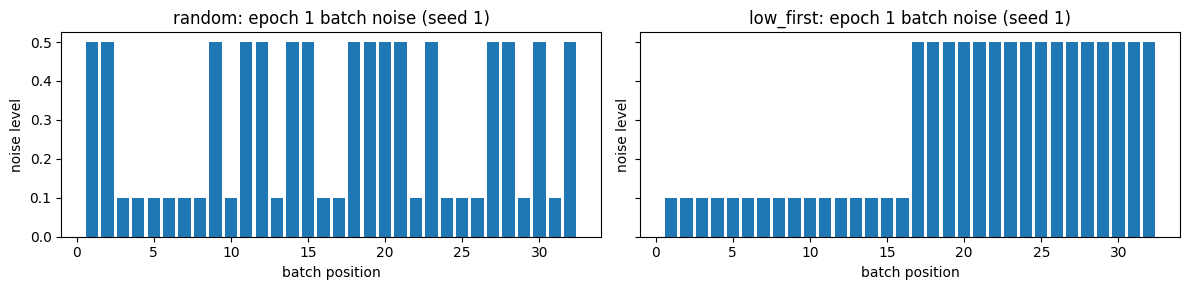

In [26]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, cond in zip(axes, ("random", "low_first")):
    r = next(r for r in results if r["condition"] == cond and r["model"] == "Linear" and r["seed"] == 1)
    ax.bar(range(1, 33), r["epoch1_batch_noise"])
    ax.set_title(f"{cond}: epoch 1 batch noise (seed 1)")
    ax.set_xlabel("batch position"); ax.set_ylabel("noise level")
plt.tight_layout(); plt.savefig(f"{OUT}/epoch1_batch_noise.png", dpi=120); plt.show()

In [27]:
metrics = ["MSE", "MAE", "MSE_0.1", "MSE_0.5", "MAE_0.1", "MAE_0.5", "train_time_s"]
summary = df.groupby(["model", "condition"])[metrics].agg(["mean", "std"])
pd.set_option("display.float_format", "{:.4f}".format)
print(summary)
summary.to_csv(f"{OUT}/summary.csv")

                      MSE           MAE        MSE_0.1        MSE_0.5         \
                     mean    std   mean    std    mean    std    mean    std   
model    condition                                                             
Linear   low_first 0.2632 0.0023 0.3846 0.0007  0.0872 0.0005  0.4392 0.0050   
         random    0.2633 0.0017 0.3846 0.0005  0.0873 0.0009  0.4394 0.0041   
MLP      low_first 0.2417 0.0052 0.3573 0.0047  0.0611 0.0048  0.4222 0.0097   
         random    0.2439 0.0044 0.3576 0.0046  0.0590 0.0036  0.4288 0.0066   
PatchTST low_first 0.2015 0.0044 0.3216 0.0066  0.0456 0.0039  0.3573 0.0066   
         random    0.1923 0.0063 0.3057 0.0070  0.0304 0.0027  0.3542 0.0100   

                   MAE_0.1        MAE_0.5        train_time_s         
                      mean    std    mean    std         mean    std  
model    condition                                                    
Linear   low_first  0.2372 0.0005  0.5320 0.0017       2.1571 0.07

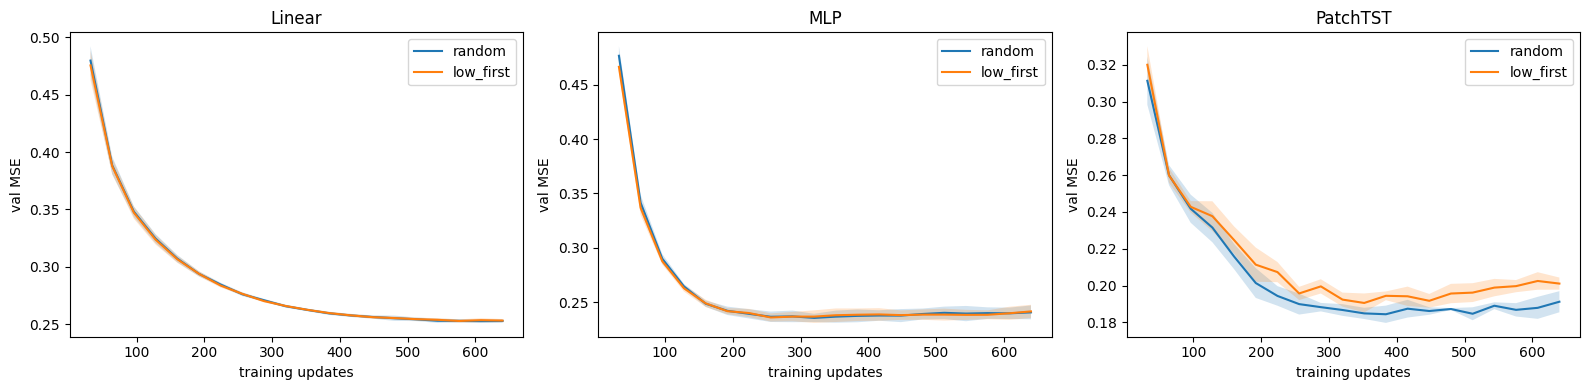

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, model_name in zip(axes, MODELS):
    for cond in ("random", "low_first"):
        curves = np.array([[v for _, v in r["val_curve"]] for r in results
                           if r["model"] == model_name and r["condition"] == cond])
        steps = [u for u, _ in results[0]["val_curve"]]
        m, s = curves.mean(0), curves.std(0)
        ax.plot(steps, m, label=cond); ax.fill_between(steps, m - s, m + s, alpha=0.2)
    ax.set_title(model_name); ax.set_xlabel("training updates"); ax.set_ylabel("val MSE"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/val_curves.png", dpi=120); plt.show()

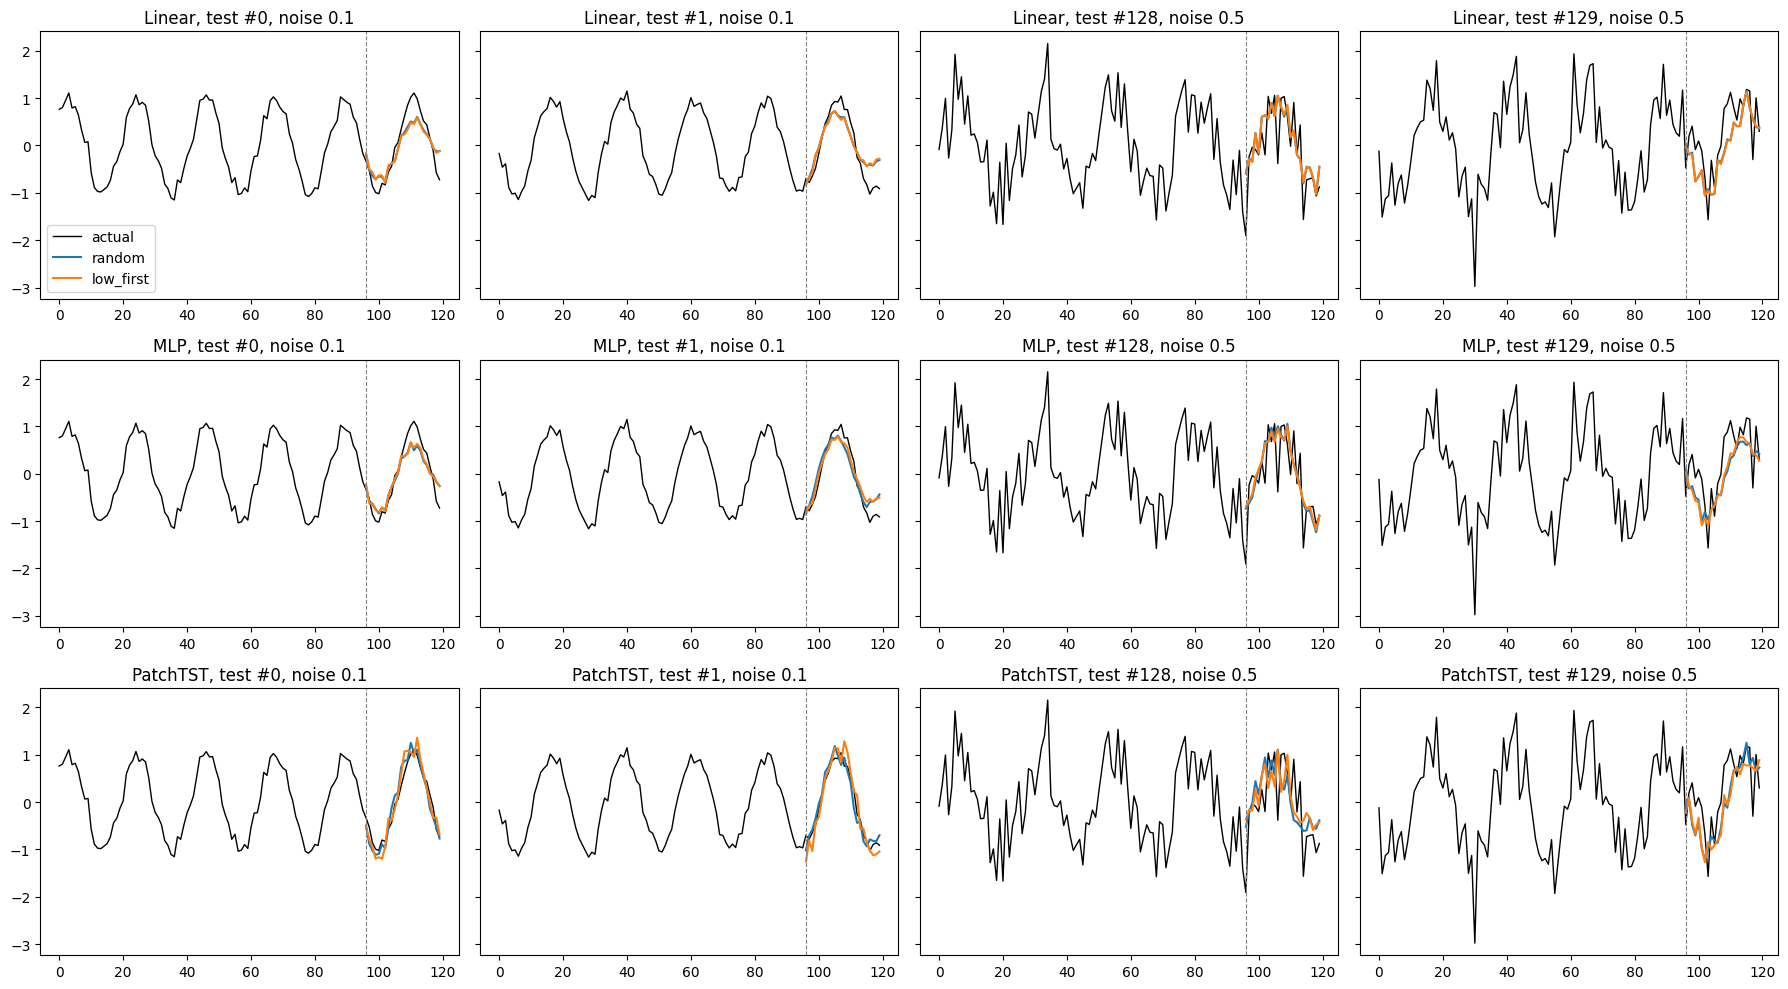

In [29]:
test = np.load(f"{DATA}/test.npz")
SHOW = [0, 1, 128, 129]   # first two of each noise group, picked before looking at errors
fig, axes = plt.subplots(len(MODELS), 4, figsize=(18, 10), sharey=True)
for row, model_name in enumerate(MODELS):
    for col, i in enumerate(SHOW):
        ax = axes[row, col]
        ax.plot(range(120), test["values"][i], color="black", lw=1, label="actual")
        for cond in ("random", "low_first"):
            p = np.load(f"{OUT}/preds_{model_name}_{cond}_seed1.npy")[i]
            ax.plot(range(96, 120), p, label=cond)
        ax.axvline(96, color="gray", ls="--", lw=0.8)
        ax.set_title(f"{model_name}, test #{i}, noise {test['noise'][i]:.1f}")
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/forecasts.png", dpi=120); plt.show()

2026-10-26 18:47:04,528 - BasicTS-launcher - INFO - Launching BasicTS training.
2026-10-26 18:47:04,723 - easytorch-env - INFO - Use devices 0.
2026-10-26 18:47:04,725 - easytorch-env - INFO - Disable TF32 mode
2026-10-26 18:47:04,733 - BasicTS - INFO - Building model.
2026-10-26 18:47:05,073 - BasicTS - INFO - Set ckpt save dir: "/content/gdrive/MyDrive/Colab Notebooks/vip/starter_runs/ckpt/PatchTST_high_first_seed1/ac3f41985497017b64fa36e4357b7764"
2026-10-26 18:47:05,080 - BasicTS-training - INFO - Initializing training.
2026-10-26 18:47:05,082 - BasicTS-training - INFO - Building train data loader.
2026-10-26 18:47:11,301 - BasicTS-training - INFO - Set optim: Adam
2026-10-26 18:47:11,302 - BasicTS-training - INFO - Building val data loader.
2026-10-26 18:47:11,307 - BasicTS-training - INFO - Building test data loader.
2026-10-26 18:47:11,311 - BasicTS-training - INFO - Total parameters: 35192
2026-10-26 18:47:11,313 - BasicTS-training - INFO - Trainable parameters: 35192
2026-10-2

              MSE           MAE        MSE_0.1        MSE_0.5         \
             mean    std   mean    std    mean    std    mean    std   
condition                                                              
high_first 0.1950 0.0059 0.3036 0.0053  0.0257 0.0015  0.3643 0.0116   
low_first  0.2015 0.0044 0.3216 0.0066  0.0456 0.0039  0.3573 0.0066   
random     0.1923 0.0063 0.3057 0.0070  0.0304 0.0027  0.3542 0.0100   

           train_time_s         
                   mean    std  
condition                       
high_first       6.9385 0.4370  
low_first        6.8498 0.4500  
random           7.0646 1.1346  

Test MSE difference from random; negative means better:
condition  high_first  low_first  random
seed                                    
1              0.0052     0.0066  0.0000
2              0.0007     0.0078  0.0000
3              0.0022     0.0131  0.0000


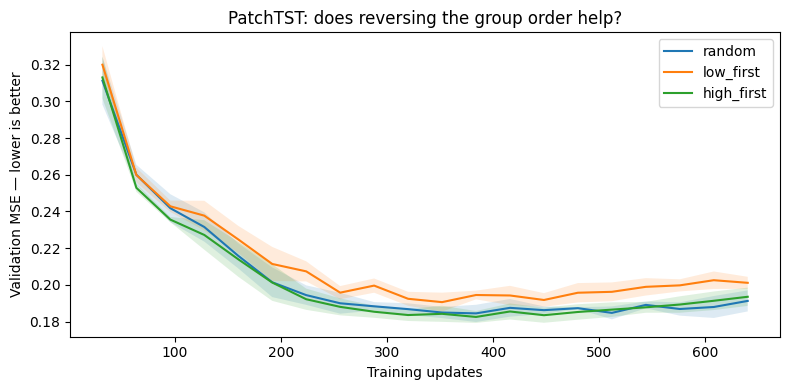

In [30]:
def batch_order(condition, rng):
    low = np.arange(len(low_batches))
    high = np.arange(len(low_batches), len(BATCHES))

    if condition == "random":
        return rng.permutation(len(BATCHES))

    low_order = rng.permutation(low)
    high_order = rng.permutation(high)

    if condition == "low_first":
        return np.concatenate([low_order, high_order])
    if condition == "high_first":
        return np.concatenate([high_order, low_order])
    raise ValueError(condition)


order = batch_order("high_first", np.random.default_rng(1001))
indices = BATCHES[order].ravel()
assert np.array_equal(np.sort(indices), np.arange(1024))
assert np.allclose(BATCH_NOISE[order[:16]], 0.5)
assert np.allclose(BATCH_NOISE[order[16:]], 0.1)

comparison = []
for condition in ("random", "low_first"):
    for seed in (1, 2, 3):
        path = f"{OUT}/result_PatchTST_{condition}_seed{seed}.json"
        with open(path) as f:
            comparison.append(json.load(f))

for seed in (1, 2, 3):
    path = f"{OUT}/result_PatchTST_high_first_seed{seed}.json"
    if os.path.exists(path):
        with open(path) as f:
            result = json.load(f)
    else:
        result = run("PatchTST", "high_first", seed)

    baseline = next(
        r for r in comparison
        if r["condition"] == "random" and r["seed"] == seed
    )
    assert result["updates"] == baseline["updates"] == 640
    assert result["init_checksum"] == baseline["init_checksum"]
    comparison.append(result)

table = pd.DataFrame(comparison)
metrics = ["MSE", "MAE", "MSE_0.1", "MSE_0.5", "train_time_s"]
print(table.groupby("condition")[metrics].agg(["mean", "std"]).round(4))

paired = table.pivot(index="seed", columns="condition", values="MSE")
print("\nTest MSE difference from random; negative means better:")
print(paired.subtract(paired["random"], axis=0).round(4))

plt.figure(figsize=(8, 4))
for condition in ("random", "low_first", "high_first"):
    curves = np.array([
        r["val_curve"] for r in comparison
        if r["condition"] == condition
    ])
    updates = curves[0, :, 0]
    errors = curves[:, :, 1]
    mean = errors.mean(axis=0)
    spread = errors.std(axis=0)
    plt.plot(updates, mean, label=condition)
    plt.fill_between(updates, mean - spread, mean + spread, alpha=0.15)

plt.xlabel("Training updates")
plt.ylabel("Validation MSE — lower is better")
plt.title("PatchTST: does reversing the group order help?")
plt.legend()
plt.tight_layout()
plt.show()